**AICE Associate <font color=red>사례실습</font> — 미세먼지 수치 예측 ① 데이터 전처리**

### <span style="color:darkgreen">**서울시 대기오염 측정 데이터로 미세먼지(PM10) 예측 준비하기**</span>
---

- 도메인 : 환경
- 목  표 : 여러 달로 나뉜 대기오염 측정 데이터를 하나로 합치고, 정제·탐색하여 PM10 예측 모델용 데이터를 만듭니다.<br>
서울시 환경정책팀은 측정소별 대기오염 물질 농도를 이용해 **미세먼지(PM10) 수치를 예측하는 모델**을 만들고자 합니다.<br>
데이터는 월별 파일(`air_data_01.csv` ~ `air_data_11.csv`)로 나뉘어 있고, 측정 장비 점검으로 인한 결측치와 장비 오류값이 섞여 있습니다.

> 📌 이 데이터는 실제 에어코리아 확정 자료와 같은 형식으로 만든 **학습용 데이터**입니다. (서울 25개 측정소, 2025년 1~11월, 1시간 단위)

---

**[ 데이터 컬럼 설명 (데이터 파일명: air_data_01.csv ~ air_data_11.csv, 인코딩 cp949) ]**

- 지역 : 측정소 지역
- 망 : 측정망 종류 (도시대기)
- 측정소코드 / 측정소명 : 측정소 식별 코드와 이름
- 측정일시 : YYYYMMDDHH 형식 (**01시 ~ 24시** 표기)
- SO2 : 아황산가스 (ppm)
- CO : 일산화탄소 (ppm)
- O3 : 오존 (ppm)
- NO2 : 이산화질소 (ppm)
- PM10 : 미세먼지 (㎍/㎥) ← **예측 대상**
- PM25 : 초미세먼지 (㎍/㎥)
- 주소 : 측정소 주소

> **다음 문항을 풀기 전에 <span style="color:red">아래 코드를 실행하세요.</span>**

In [1]:
import platform
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
import warnings
warnings.filterwarnings('ignore')

# OS에 따라서 한글 폰트 로드
os_name = platform.system()

if os_name == 'Linux':
    font_names = [f.name for f in fm.fontManager.ttflist]
    for cand in ['NanumGothicCoding', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
        if cand in font_names:
            plt.rc('font', family=cand)
            break
    print("(리눅스) 한글폰트 로드 완료")
elif os_name == 'Windows':
    font_path = 'C:\\Windows\\Fonts\\malgun.ttf'
    font = fm.FontProperties(fname=font_path).get_name()
    mpl.rc('font', family=font)
    print("(윈도우) 한글폰트 로드 완료")
elif os_name == 'Darwin':
    plt.rc('font', family='AppleGothic')
    print("(맥) 한글폰트 로드 완료")
else:
    print(f"알 수 없는 OS입니다: {os_name}")

# 마이너스 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

(리눅스) 한글폰트 로드 완료


<br>

## <font color=blue>**<데이터 불러오기>**</font>

### **1. 한글이 포함된 CSV 파일 읽기**
---
- `air_data_01.csv`를 `pd.read_csv`로 그냥 읽으면 어떤 에러가 나는지 확인하세요.
- 인코딩 옵션을 지정해 다시 읽고, 첫 5개 행을 출력하세요.
---

In [2]:
# [1번 문항] 여기에 답안코드를 작성하고 실행하세요.

In [3]:
# [1번 정답]
try:
    pd.read_csv('air_data_01.csv')
except UnicodeDecodeError as e:
    print('UnicodeDecodeError 발생:', str(e)[:80])

sample = pd.read_csv('air_data_01.csv', encoding='cp949')
sample.head()

UnicodeDecodeError 발생: 'utf-8' codec can't decode byte 0xc1 in position 0: invalid start byte


,지역,망,측정소코드,측정소명,측정일시,SO2,CO,O3,NO2,PM10,PM25,주소
0,서울 중구,도시대기,111121,중구,2025010101,0.0039,0.6,0.0037,0.0233,45.0,23.0,서울 중구 덕수궁길 15
1,서울 종로구,도시대기,111123,종로구,2025010101,0.0028,0.5,0.0010,0.0193,46.0,29.0,서울 종로구 종로35가길 19
2,서울 용산구,도시대기,111131,용산구,2025010101,0.0029,0.6,0.0053,0.0254,41.0,25.0,서울 용산구 한남대로 136
3,서울 광진구,도시대기,111141,광진구,2025010101,0.0028,0.5,0.0010,0.0214,52.0,26.0,서울 광진구 자양로 117
4,서울 성동구,도시대기,111142,성동구,2025010101,0.0038,0.6,0.0022,0.0203,34.0,19.0,서울 성동구 뚝섬로3길 18


> 💡 한국 공공데이터의 CSV는 **cp949(또는 euc-kr)** 인코딩인 경우가 많습니다. `UnicodeDecodeError`가 나면 `encoding='cp949'`를 먼저 시도하세요.

<br>

### **2. 11개의 월별 파일을 하나의 데이터프레임 air로 합치세요.**
---
- `glob`으로 `air_data_*.csv` 파일 목록을 찾아 이름순으로 정렬하세요.
- 각 파일을 cp949로 읽어 리스트에 담은 뒤, `pd.concat`으로 합치고 index를 새로 매기세요.
- air의 행 개수를 '답안2'에 저장하세요.
---

In [4]:
# [2번 문항] 여기에 답안코드를 작성하고 실행하세요.

In [5]:
# [2번 정답]
import glob

files = sorted(glob.glob('air_data_*.csv'))
print(files)

df_list = [pd.read_csv(f, encoding='cp949') for f in files]
air = pd.concat(df_list, ignore_index=True)
print(air.shape)

답안2 = len(air)
print('답안2 =', 답안2)

['air_data_01.csv', 'air_data_02.csv', 'air_data_03.csv', 'air_data_04.csv', 'air_data_05.csv', 'air_data_06.csv', 'air_data_07.csv', 'air_data_08.csv', 'air_data_09.csv', 'air_data_10.csv', 'air_data_11.csv']


(200400, 12)
답안2 = 200400


<br>

### **3. 데이터 구조를 파악하세요.**
---
- info(), describe()로 자료형과 기초 통계를 확인하세요.
- 측정소 개수를 '답안3_1'에, 측정소별 행 개수가 모두 같은지(True/False)를 '답안3_2'에 저장하세요.
---

In [6]:
# [3번 문항] 여기에 답안코드를 작성하고 실행하세요.

In [7]:
# [3번 정답]
air.info()
display(air.describe().T)

cnt = air['측정소명'].value_counts()
print(cnt.head())
답안3_1 = air['측정소명'].nunique()
답안3_2 = cnt.nunique() == 1
print(답안3_1, 답안3_2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200400 entries, 0 to 200399
Data columns (total 12 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   지역      200400 non-null  object 
 1   망       200400 non-null  object 
 2   측정소코드   200400 non-null  int64  
 3   측정소명    200400 non-null  object 
 4   측정일시    200400 non-null  int64  
 5   SO2     196339 non-null  float64
 6   CO      196339 non-null  float64
 7   O3      196339 non-null  float64
 8   NO2     196339 non-null  float64
 9   PM10    197393 non-null  float64
 10  PM25    197408 non-null  float64
 11  주소      200400 non-null  object 
dtypes: float64(6), int64(2), object(4)
memory usage: 18.3+ MB


,count,mean,std,min,25%,50%,75%,max
측정소코드,200400.0,1.112110e+05,59.933766,1.111210e+05,1.111520e+05,1.112120e+05,1.112620e+05,1.113110e+05
측정일시,200400.0,2.025062e+09,31566.304680,2.025010e+09,2.025033e+09,2.025062e+09,2.025091e+09,2.025113e+09
SO2,196339.0,3.579670e-03,0.000600,1.000000e-03,3.200000e-03,3.600000e-03,4.000000e-03,6.900000e-03
CO,196339.0,5.573248e-01,0.106044,2.000000e-01,5.000000e-01,5.000000e-01,6.000000e-01,1.300000e+00
O3,196339.0,2.348309e-02,0.017176,1.000000e-03,1.040000e-02,1.800000e-02,3.440000e-02,8.650000e-02
NO2,196339.0,2.596324e-02,0.011128,2.000000e-03,1.810000e-02,2.450000e-02,3.210000e-02,1.127000e-01
PM10,197393.0,4.859599e+01,40.679463,3.000000e+00,2.500000e+01,4.000000e+01,6.100000e+01,9.990000e+02
PM25,197408.0,2.576191e+01,17.202664,1.000000e+00,1.400000e+01,2.200000e+01,3.400000e+01,1.410000e+02


측정소명
중구     8016
종로구    8016
용산구    8016
광진구    8016
성동구    8016
Name: count, dtype: int64
25 True


<br>

## <font color=blue>**<데이터 정제>**</font>

### **4. 측정일시를 날짜/시간(datetime) 형식으로 바꾸세요.**
---
- 측정일시는 `2025010124` 처럼 **24시**가 있어 `pd.to_datetime(..., format='%Y%m%d%H')`으로 바로 변환하면 에러가 납니다.
- 날짜 부분(`측정일시 // 100`)과 시간 부분(`측정일시 % 100`)을 나눈 뒤,<br>
  `날짜 + 시간(timedelta)` 으로 계산해 **'일시'** 컬럼을 만드세요. (24시는 다음날 0시가 됩니다)
- 결과를 확인하고, 2025010124 가 변환된 값을 '답안4'에 문자열로 저장하세요. (예: '2025-01-01 00:00:00')
---

In [8]:
# [4번 문항] 여기에 답안코드를 작성하고 실행하세요.

In [9]:
# [4번 정답]
try:
    pd.to_datetime(air['측정일시'].astype(str), format='%Y%m%d%H')
except ValueError as e:
    print('바로 변환하면 에러:', str(e)[:90])

date_part = pd.to_datetime((air['측정일시'] // 100).astype(str), format='%Y%m%d')
hour_part = pd.to_timedelta(air['측정일시'] % 100, unit='h')
air['일시'] = date_part + hour_part

print(air.loc[air['측정일시'] == 2025010124, ['측정일시', '일시']].head(1))
답안4 = '2025-01-02 00:00:00'

바로 변환하면 에러: unconverted data remains when parsing with format "%Y%m%d%H": "4", at position 23. You mig


           측정일시         일시
575  2025010124 2025-01-02


<br>

### **5. 분석에 필요 없는 컬럼을 삭제하세요.**
---
- '지역', '망', '측정소코드', '주소', '측정일시' 컬럼을 삭제하세요. (측정소명과 일시로 충분)
- 결과는 air에 다시 저장하고, 남은 컬럼 목록을 출력하세요.
---

In [10]:
# [5번 문항] 여기에 답안코드를 작성하고 실행하세요.

In [11]:
# [5번 정답]
air = air.drop(['지역', '망', '측정소코드', '주소', '측정일시'], axis=1)
print(air.columns.tolist())

['측정소명', 'SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '일시']


<br>

### **6. 결측치를 확인하고 처리하세요.**

- **[6-1] 컬럼별 결측치 개수와 비율(%)을 확인하세요. PM10의 결측치 개수를 '답안6_1'에 저장하세요.**
---

In [12]:
# [6-1번 문항] 여기에 답안코드를 작성하고 실행하세요.

In [13]:
# [6-1번 정답]
na = pd.DataFrame({'결측수': air.isnull().sum(), '비율(%)': (air.isnull().mean() * 100).round(2)})
display(na)
답안6_1 = air['PM10'].isnull().sum()
print('답안6_1 =', 답안6_1)

,결측수,비율(%)
측정소명,0,0.00
SO2,4061,2.03
CO,4061,2.03
O3,4061,2.03
NO2,4061,2.03
PM10,3007,1.50
PM25,2992,1.49
일시,0,0.00


답안6_1 = 3007


- **[6-2] 아래 가이드에 따라 결측치를 처리하고 결과를 air_na에 저장하세요.**
    - 예측 대상인 **PM10이 결측인 행은 삭제**합니다. (정답이 없는 데이터는 학습에 쓸 수 없음)
    - SO2, CO, O3, NO2, PM25는 시간 순서가 있는 데이터이므로, **측정소별로 일시 순 정렬 후 선형 보간(interpolate)** 으로 채우세요.
    - 보간 후에도 남는 결측(각 측정소의 맨 앞/뒤)은 `bfill`, `ffill`로 채우세요.
    - 결측치가 없는지 확인하세요.
---

In [14]:
# [6-2번 문항] 여기에 답안코드를 작성하고 실행하세요.

In [15]:
# [6-2번 정답]
air_na = air.dropna(subset=['PM10']).sort_values(['측정소명', '일시']).reset_index(drop=True)

cols = ['SO2', 'CO', 'O3', 'NO2', 'PM25']
air_na[cols] = air_na.groupby('측정소명')[cols].transform(lambda s: s.interpolate().bfill().ffill())

print(air_na.isnull().sum())
print(air.shape, '->', air_na.shape)

측정소명    0
SO2     0
CO      0
O3      0
NO2     0
PM10    0
PM25    0
일시      0
dtype: int64
(200400, 8) -> (197393, 8)


> 💡 시계열 데이터에서 평균값으로 채우면 앞뒤 시간과 동떨어진 값이 들어갑니다. **같은 측정소의 앞뒤 시간 값으로 보간**하는 것이 자연스럽습니다.

<br>

### **7. PM10의 이상치를 처리하세요.**
---
- boxplot과 describe로 PM10 분포를 확인하세요.
- IQR 기준 upper fence를 계산하고, 이를 넘는 행의 개수를 출력하세요.
- PM10 측정 장비의 **오류값(900 이상)** 만 삭제하고, 결과를 air_clean에 저장하세요. 삭제된 행 수를 '답안7'에 저장하세요.
---

In [16]:
# [7번 문항] 여기에 답안코드를 작성하고 실행하세요.

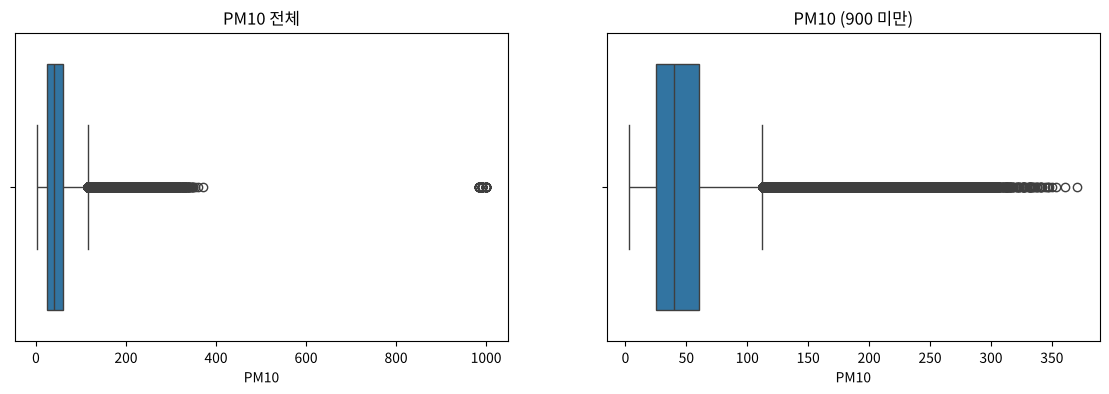

IQR upper fence = 115.0, 초과 행 수 = 8616
답안7 = 66


In [17]:
# [7번 정답]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=air_na['PM10'], ax=axes[0])
axes[0].set_title('PM10 전체')
sns.boxplot(x=air_na.loc[air_na['PM10'] < 900, 'PM10'], ax=axes[1])
axes[1].set_title('PM10 (900 미만)')
plt.show()

q1, q3 = air_na['PM10'].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print(f'IQR upper fence = {upper:.1f}, 초과 행 수 = {(air_na["PM10"] > upper).sum()}')

air_clean = air_na[air_na['PM10'] < 900].reset_index(drop=True)
답안7 = len(air_na) - len(air_clean)
print('답안7 =', 답안7)

> 💡 **왜 IQR로 다 지우지 않을까?** IQR 기준을 넘는 높은 PM10 값의 대부분은 **봄철 황사 같은 실제 고농도 사건**입니다.
> 이런 값을 지우면 모델이 정작 중요한 '미세먼지 나쁨' 상황을 배우지 못합니다.
> 통계적 기준은 참고만 하고, **도메인 지식(측정 가능 범위, 장비 오류 코드)** 으로 판단해야 합니다.
> (시험에서는 문항 가이드에 지정된 기준을 따르면 됩니다.)

<br>

## <font color=blue>**<Feature Engineering>**</font>

### **8. 일시 컬럼에서 시간 관련 파생변수를 만드세요.**
---
- month(월), day(일), hour(시), weekday(요일, 월=0 ~ 일=6) 컬럼을 만드세요. (`.dt` 접근자 사용)
- season 컬럼: 3~5월 '봄', 6~8월 '여름', 9~11월 '가을', 12~2월 '겨울'
- PM10 등급 컬럼 'PM10_grade': 0~30 '좋음', 31~80 '보통', 81~150 '나쁨', 151 이상 '매우나쁨' (`pd.cut` 사용)
---

In [18]:
# [8번 문항] 여기에 답안코드를 작성하고 실행하세요.

In [19]:
# [8번 정답]
air_clean['month'] = air_clean['일시'].dt.month
air_clean['day'] = air_clean['일시'].dt.day
air_clean['hour'] = air_clean['일시'].dt.hour
air_clean['weekday'] = air_clean['일시'].dt.weekday

season_map = {3: '봄', 4: '봄', 5: '봄', 6: '여름', 7: '여름', 8: '여름', 9: '가을', 10: '가을', 11: '가을', 12: '겨울', 1: '겨울', 2: '겨울'}
air_clean['season'] = air_clean['month'].map(season_map)

air_clean['PM10_grade'] = pd.cut(air_clean['PM10'], bins=[-1, 30, 80, 150, 10000], labels=['좋음', '보통', '나쁨', '매우나쁨'])
air_clean[['일시', 'month', 'day', 'hour', 'weekday', 'season', 'PM10', 'PM10_grade']].head()

,일시,month,day,hour,weekday,season,PM10,PM10_grade
0,2025-01-01 01:00:00,1,1,1,2,겨울,53.0,보통
1,2025-01-01 02:00:00,1,1,2,2,겨울,37.0,보통
2,2025-01-01 03:00:00,1,1,3,2,겨울,35.0,보통
3,2025-01-01 04:00:00,1,1,4,2,겨울,42.0,보통
4,2025-01-01 05:00:00,1,1,5,2,겨울,42.0,보통


> 📌 24시를 다음날 0시로 바꿨기 때문에 1월 1일 24시 측정값은 `1월 2일 0시`로 집계됩니다. (11월 30일 24시 → 12월 1일)
> 이런 경계 처리 방식은 분석 목적에 따라 정하면 됩니다.

<br>

## <font color=blue>**<탐색적 데이터 분석(EDA)>**</font>

### **9. 월별·시간대별 PM10 패턴을 시각화하세요.**
---
- 왼쪽: 월별 평균 PM10 barplot (x='month', y='PM10')
- 오른쪽: 시간대별 평균 PM10 lineplot (x='hour', y='PM10')
- 평균 PM10이 가장 높은 월을 '답안9'에 저장하세요.
---

In [20]:
# [9번 문항] 여기에 답안코드를 작성하고 실행하세요.

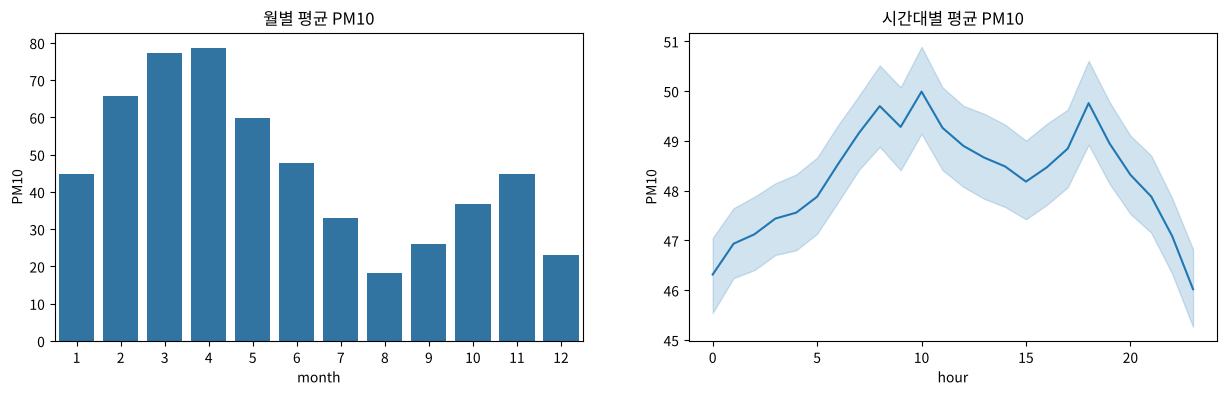

month
1     44.7
2     65.7
3     77.4
4     78.7
5     59.8
6     47.9
7     33.0
8     18.2
9     26.1
10    36.7
11    44.9
12    23.2
Name: PM10, dtype: float64
답안9 = 4


In [21]:
# [9번 정답]
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
sns.barplot(data=air_clean, x='month', y='PM10', errorbar=None, ax=axes[0])
sns.lineplot(data=air_clean, x='hour', y='PM10', ax=axes[1])
axes[0].set_title('월별 평균 PM10')
axes[1].set_title('시간대별 평균 PM10')
plt.show()

monthly = air_clean.groupby('month')['PM10'].mean().round(1)
print(monthly)
답안9 = monthly.idxmax()
print('답안9 =', 답안9)

<br>

### **10. PM10 등급 분포와 측정소별 차이를 확인하세요.**
---
- 왼쪽: 계절(season)별 PM10 등급 countplot (x='season', hue='PM10_grade', order=['봄','여름','가을','겨울'])
- 오른쪽: 측정소별 평균 PM10 상위 10개 barplot (가로 막대)
- '매우나쁨' 등급이 가장 많이 발생한 계절을 '답안10'에 저장하세요.
---

In [22]:
# [10번 문항] 여기에 답안코드를 작성하고 실행하세요.

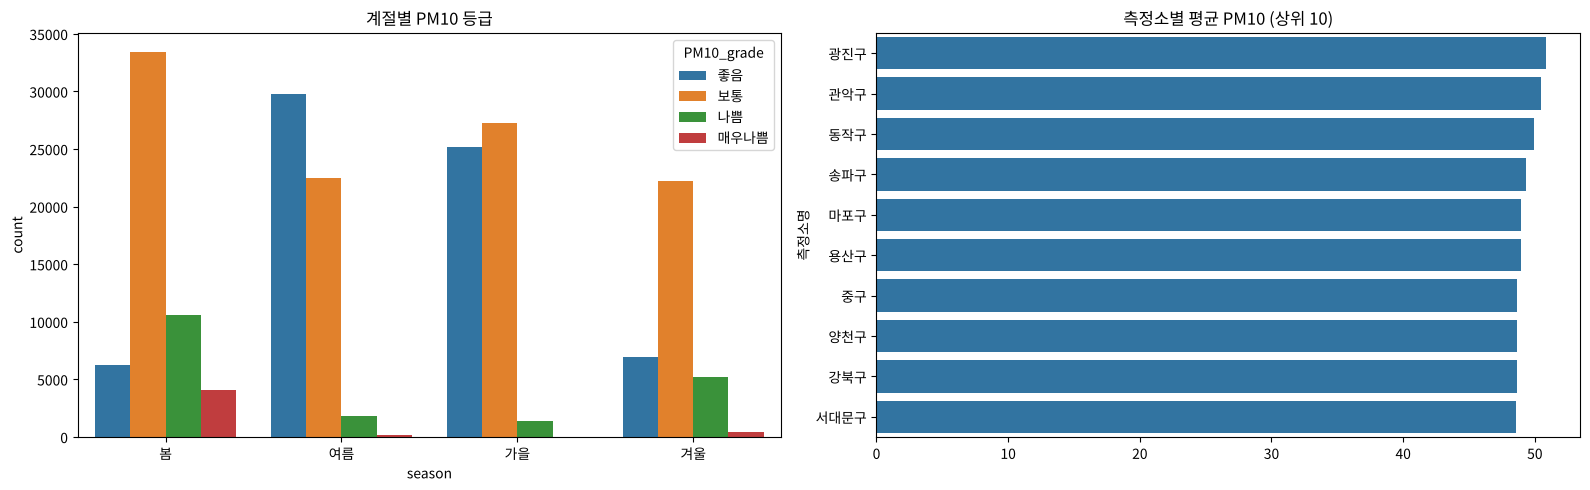

PM10_grade     좋음     보통     나쁨  매우나쁨
season                               
가을          25141  27246   1418     0
겨울           6983  22196   5230   455
봄            6255  33405  10610  4060
여름          29821  22527   1803   177


In [23]:
# [10번 정답]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.countplot(data=air_clean, x='season', hue='PM10_grade', order=['봄', '여름', '가을', '겨울'], ax=axes[0])
axes[0].set_title('계절별 PM10 등급')

top10 = air_clean.groupby('측정소명')['PM10'].mean().sort_values(ascending=False).head(10)
sns.barplot(x=top10.values, y=top10.index, ax=axes[1])
axes[1].set_title('측정소별 평균 PM10 (상위 10)')
plt.tight_layout()
plt.show()

print(pd.crosstab(air_clean['season'], air_clean['PM10_grade']))
답안10 = '봄'

<br>

### **11. 대기오염 물질 간 상관관계를 heatmap으로 확인하세요.**
---
- 대상: 'SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25'
- annot=True, fmt='.2f', cmap='coolwarm'
- PM10과 상관계수가 가장 높은 변수를 '답안11_1'에, 음의 상관이 있는 변수를 '답안11_2'에 저장하세요.
---

In [24]:
# [11번 문항] 여기에 답안코드를 작성하고 실행하세요.

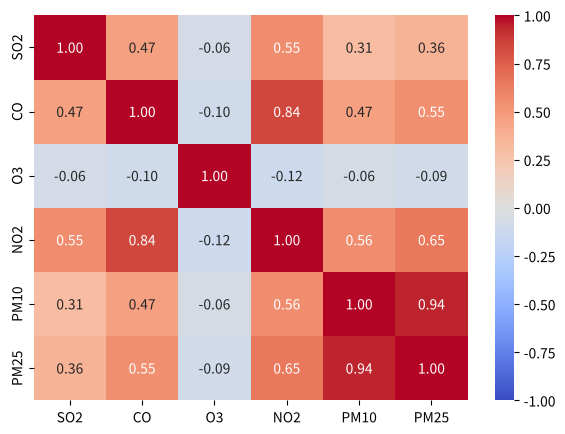

O3     -0.056929
SO2     0.307938
CO      0.467602
NO2     0.555583
PM25    0.943352
Name: PM10, dtype: float64
PM25 O3


In [25]:
# [11번 정답]
corr = air_clean[['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

print(corr['PM10'].drop('PM10').sort_values())
답안11_1 = corr['PM10'].drop('PM10').idxmax()
답안11_2 = corr['PM10'].drop('PM10').idxmin()
print(답안11_1, 답안11_2)

<br>

### **12. 전처리 결과를 저장하세요.**
---
- air_clean을 'air_preprocessed.csv'로 저장하세요. (index 제외, encoding='utf-8-sig' — 엑셀에서도 한글이 깨지지 않음)
- 저장한 파일을 다시 읽어 shape를 확인하세요.
---

In [26]:
# [12번 문항] 여기에 답안코드를 작성하고 실행하세요.

In [27]:
# [12번 정답]
air_clean.to_csv('air_preprocessed.csv', index=False, encoding='utf-8-sig')
check = pd.read_csv('air_preprocessed.csv')
print(check.shape)
check.head(3)

(197327, 14)


,측정소명,SO2,CO,O3,NO2,PM10,PM25,일시,month,day,hour,weekday,season,PM10_grade
0,강남구,0.0039,0.4,0.0090,0.0216,53.0,28.0,2025-01-01 01:00:00,1,1,1,2,겨울,보통
1,강남구,0.0036,0.5,0.0081,0.0253,37.0,20.0,2025-01-01 02:00:00,1,1,2,2,겨울,보통
2,강남구,0.0024,0.5,0.0057,0.0164,35.0,19.0,2025-01-01 03:00:00,1,1,3,2,겨울,보통


<br>

### **전처리가 완료되었습니다. 다음 노트북(`16.사례실습_미세먼지수치예측_02.모델링`)에서 PM10 예측 모델을 만듭니다.**